## Day 29 — Task Sheet

## Model Interpretation with SHAP and Partial Dependence

In [ ]:

# 1. Import libraries
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, roc_auc_score

from xgboost import XGBClassifier
import shap

# 2. Load dataset
df = pd.read_csv("titanic.csv")

# 3. Normalize column names
df.columns = df.columns.str.strip().str.lower()

print("Dataset shape:", df.shape)
print(df.head())

# 4. Handle missing values

# Age median based on pclass and sex
df["age"] = df.groupby(
    ["pclass", "sex"]
)["age"].transform(
    lambda x: x.fillna(x.median())
)

# Fill remaining missing age values
df["age"] = df["age"].fillna(df["age"].median())

# Fill missing fare values
df["fare"] = df["fare"].fillna(df["fare"].median())

# 5. Create numeric sex_male feature
df["sex_male"] = (df["sex"] == "male").astype(int)

# 6. Select features and target
features = [
    "pclass",
    "sex_male",
    "age",
    "sibsp",
    "parch",
    "fare"
]

X = df[features]
y = df["survived"]

# 7. Stratified 80/20 split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

# 8. Train XGBoost classifier
model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.1,
    max_depth=3,
    random_state=42,
    eval_metric="logloss"
)

model.fit(X_train, y_train)

# 9. Make predictions
y_pred = model.predict(X_test)

# 10. Calculate test AUC
y_probability = model.predict_proba(X_test)[:, 1]

test_auc = roc_auc_score(y_test, y_probability)

print("\nModel Results")
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Test AUC:", round(test_auc, 4))


## Part A — Global versus local

## TASK 01 — Establish the global picture first

Permutation Importance Ranking:
 Feature  Importance      Std
sex_male    0.236792 0.028533
    fare    0.046172 0.018179
  pclass    0.040858 0.012358
   parch    0.003257 0.005622
   sibsp   -0.001451 0.006476
     age   -0.006674 0.011841


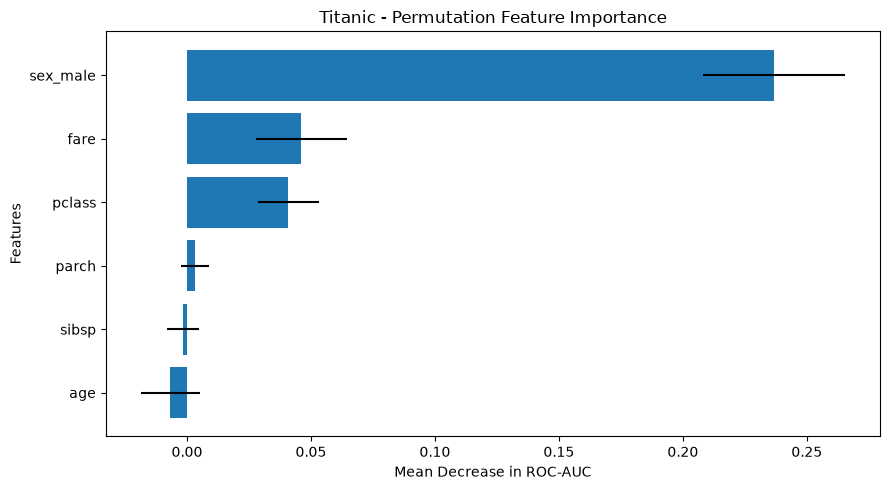

In [5]:

# 1. Import required libraries
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.inspection import permutation_importance

# 2. Calculate permutation importance on test data
perm_result = permutation_importance(
    model,
    X_test,
    y_test,
    n_repeats=20,
    scoring="roc_auc",
    random_state=42,
    n_jobs=-1
)

# 3. Create importance DataFrame
importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": perm_result.importances_mean,
    "Std": perm_result.importances_std
})

# 4. Sort features by importance
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

# 5. Display feature ranking
print("Permutation Importance Ranking:")
print(importance_df.to_string(index=False))

# 6. Plot horizontal bar chart
plt.figure(figsize=(9, 5))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"],
    xerr=importance_df["Std"]
)

plt.xlabel("Mean Decrease in ROC-AUC")
plt.ylabel("Features")
plt.title("Titanic - Permutation Feature Importance")

# Show most important feature at the top
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()


### **Global vs Local Interpretation**

**1. Global Interpretation**

Describes how the model behaves across the entire dataset. It shows which features are most important overall.

Example: Permutation importance ranks `sex_male`, `pclass`, and `fare` according to their impact on the model's ROC-AUC.

**2. Local Interpretation**

Explains why the model made a prediction for one specific passenger.

Example: Why did the model predict that a particular Titanic passenger would survive or not survive?

### **What does Global Ranking Leave Out?**

Global feature importance does not explain:

- Why one specific passenger received a particular prediction.
- Whether a feature increases or decreases survival probability.
- How different features interact for an individual passenger.

**Conclusion:** Global interpretation explains overall model behaviour, while local interpretation explains an individual prediction.

## TASK 02 — Prove local accuracy yourself

In [24]:

# 1. Import libraries
import shap
import numpy as np

# 2. Create SHAP TreeExplainer
explainer = shap.TreeExplainer(model)

# 3. Calculate SHAP values for test data
shap_values = explainer.shap_values(X_test)

# 4. Print SHAP values shape
print("SHAP Values Shape:", shap_values.shape)

# 5. Print expected value (base value)
print("Expected Value:", explainer.expected_value)

# 6. Get raw model output for test data
raw = model.predict(X_test, output_margin=True)

# 7. Check three different rows
for i in [0, 1, 2]:

    # Calculate reconstructed output
    recon = float(explainer.expected_value) + shap_values[i].sum()

    # Compare reconstructed output with actual raw output
    match = np.isclose(recon, raw[i])

    print(f"\nRow {i}")
    print("Base Value:", float(explainer.expected_value))
    print("Sum of SHAP Values:", shap_values[i].sum())
    print("Reconstructed Output:", recon)
    print("Model Raw Output:", raw[i])
    print("Match:", match)


SHAP Values Shape: (200, 6)
Expected Value: -0.24494131

Row 0
Base Value: -0.24494130909442902
Sum of SHAP Values: 2.5066946
Reconstructed Output: 2.2617533
Model Raw Output: 2.2617524
Match: True

Row 1
Base Value: -0.24494130909442902
Sum of SHAP Values: 0.51910263
Reconstructed Output: 0.27416134
Model Raw Output: 0.27416083
Match: True

Row 2
Base Value: -0.24494130909442902
Sum of SHAP Values: 3.8942766
Reconstructed Output: 3.6493354
Model Raw Output: 3.6493363
Match: True


Q1. Why does SHAP values array have this shape?

The SHAP array has one row per test passenger and one column per input feature.

Q2. What is expected_value?

Expected value represents the baseline raw model output before individual feature contributions are added.

Q3. What does SHAP reconstruction prove?

It verifies that the base value plus the sum of all SHAP feature contributions equals the model's raw output for each passenger.

## Part B — Read the four SHAP plots

## TASK 03 — Summary and beeswarm

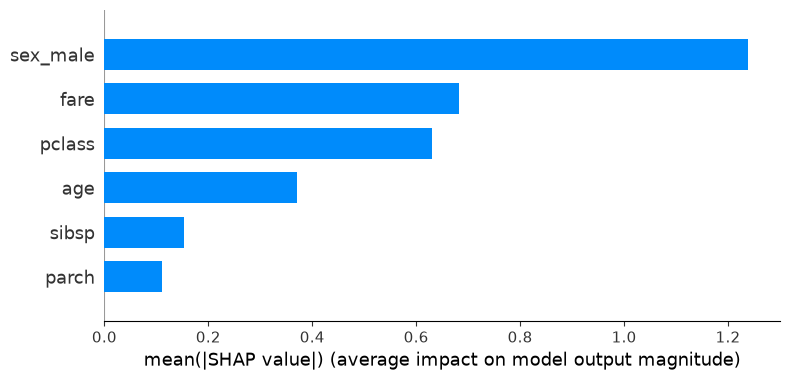

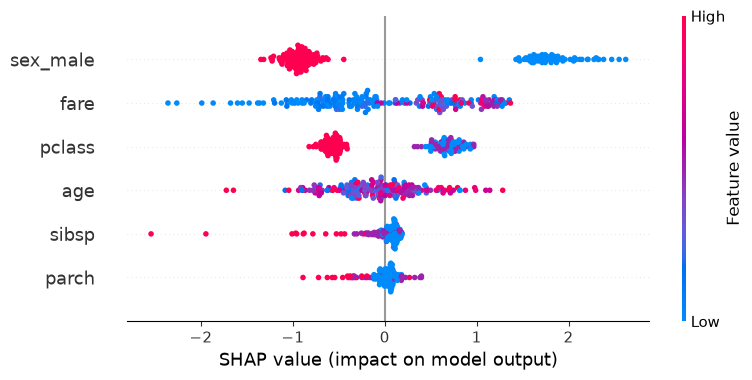


SHAP vs Permutation Ranking:
SHAP Ranking Permutation Ranking
    sex_male            sex_male
        fare                fare
      pclass              pclass
         age                 age
       sibsp               sibsp
       parch               parch

Top Two SHAP Features:
 Feature  SHAP_Importance
sex_male         1.238137
    fare         0.682719

Beeswarm Interpretation:
Red dots = High feature values
Blue dots = Low feature values
Right side = Pushes prediction towards survival
Left side = Pushes prediction towards non-survival

Check these features in your Beeswarm plot:
- sex_male
- fare


In [31]:

# TITANIC: SHAP BAR PLOT & BEESWARM ANALYSIS

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Calculate mean absolute SHAP importance
shap_importance = np.abs(shap_values).mean(axis=0)

# 2. Create SHAP ranking DataFrame
shap_df = pd.DataFrame({
    "Feature": X_test.columns,
    "SHAP_Importance": shap_importance
})

shap_df = shap_df.sort_values(
    by="SHAP_Importance",
    ascending=False
)

# 3. SHAP Bar Summary Plot
shap.summary_plot(
    shap_values,
    X_test,
    plot_type="bar"
)

# 4. SHAP Beeswarm Summary Plot
shap.summary_plot(
    shap_values,
    X_test
)

# 5. Compare SHAP and Permutation rankings
perm_rank = importance_df.sort_values(
    by="Importance",
    ascending=False
)["Feature"].tolist()

comparison = pd.DataFrame({
    "SHAP Ranking": shap_df["Feature"].tolist(),
    "Permutation Ranking": perm_rank
})

print("\nSHAP vs Permutation Ranking:")
print(comparison.to_string(index=False))

# 6. Display top two SHAP features
top_two = shap_df.head(2)

print("\nTop Two SHAP Features:")
print(top_two.to_string(index=False))

# 7. Display interpretation instructions
print("\nBeeswarm Interpretation:")
print("Red dots = High feature values")
print("Blue dots = Low feature values")
print("Right side = Pushes prediction towards survival")
print("Left side = Pushes prediction towards non-survival")

# 8. Display top two feature values
print("\nCheck these features in your Beeswarm plot:")
for feature in top_two["Feature"]:
    print("-", feature)


1. Compare SHAP and Permutation rankings:

Both methods identify important features, but their rankings may differ because SHAP measures average feature contributions, while permutation importance measures the decrease in model ROC-AUC after shuffling.

2. Top two features direction:

Check the red dots in your beeswarm plot.
- Red dots on the right = High values push predictions towards survival.
- Red dots on the left = High values push predictions towards non-survival.
3. What information does Beeswarm show that Bar Chart discards?

The beeswarm plot shows individual feature contributions, their direction, and distribution across passengers. The bar chart only shows average absolute feature importance.

Important: Your actual top two features and their directions must come from your generated plots, not guessed values.



**Q1. If the two rankings disagree, which would you trust, and what would you check first?**

I would check both because they measure different things. First, I would check feature correlations, data quality, and whether shuffling one feature affects other related features.

**Q2. For&#x20;**`sex_male`**, why do the dots form two tight vertical clusters rather than a spread?**

Because `sex_male` is a binary feature with only two values: 0 (female) and 1 (male), so SHAP dots form two vertical clusters.

## TASK 04 — Explain three individual passengers


Most Confident Survival
Test Row Index: 133

Passenger Feature Values:
pclass       1.00
sex_male     0.00
age         36.50
sibsp        0.00
parch        0.00
fare        80.28
Name: 821, dtype: float64

Predicted Survival Probability: 0.9935
Predicted Class: Survived

SHAP Contributions:
 Feature  SHAP Value
  pclass      0.7896
sex_male      2.1452
     age      1.0995
   sibsp      0.1088
   parch      0.0173
    fare      1.1105

SHAP Waterfall Plot:


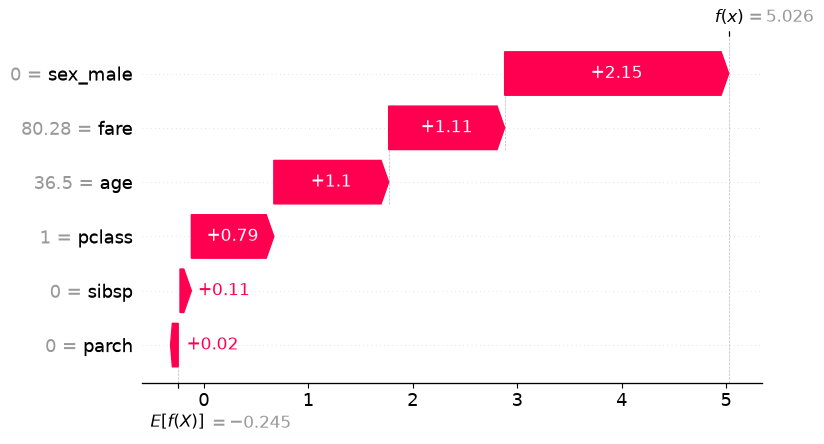


Most Confident Death
Test Row Index: 103

Passenger Feature Values:
pclass       3.00
sex_male     1.00
age         22.60
sibsp        4.00
parch        0.00
fare         7.66
Name: 791, dtype: float64

Predicted Survival Probability: 0.0014
Predicted Class: Did Not Survive

SHAP Contributions:
 Feature  SHAP Value
  pclass     -0.4970
sex_male     -1.1335
     age     -0.1289
   sibsp     -2.5422
   parch     -0.0182
    fare     -1.9903

SHAP Waterfall Plot:


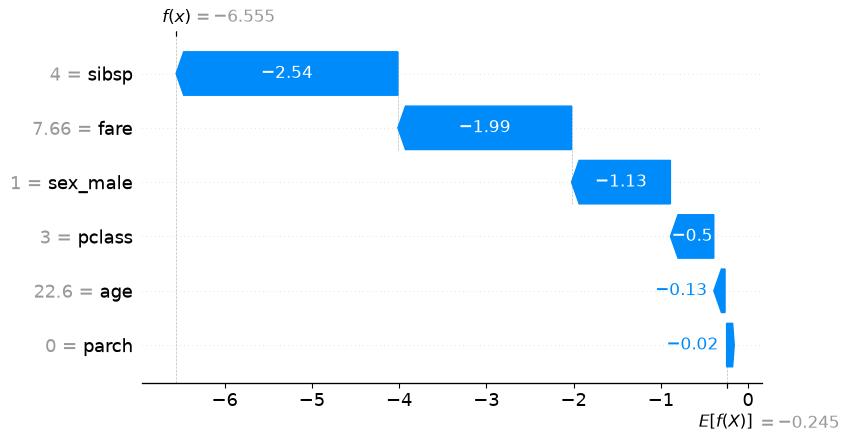


Uncertain Passenger
Test Row Index: 106

Passenger Feature Values:
pclass       3.00
sex_male     0.00
age         23.80
sibsp        0.00
parch        0.00
fare         6.64
Name: 886, dtype: float64

Predicted Survival Probability: 0.498
Predicted Class: Did Not Survive

SHAP Contributions:
 Feature  SHAP Value
  pclass     -0.5437
sex_male      1.8444
     age     -0.2168
   sibsp      0.1747
   parch     -0.0643
    fare     -0.9574

SHAP Waterfall Plot:


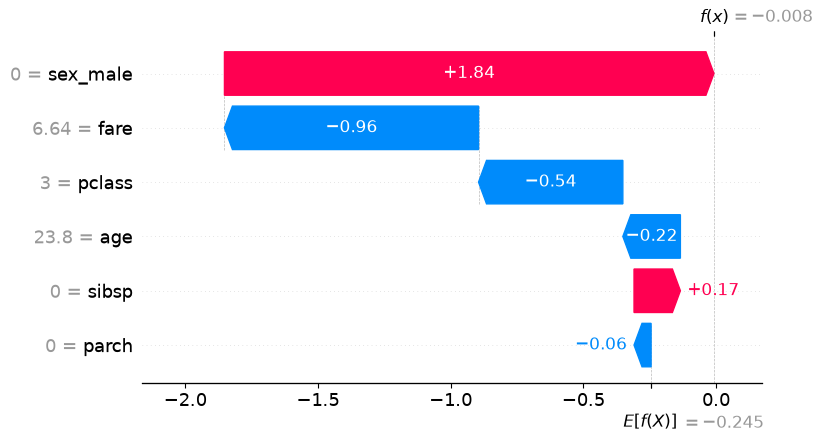


UNCERTAIN PASSENGER ANALYSIS
Predicted Survival Probability: 0.498
Positive SHAP Contributions: [1.8444 0.1747]
Negative SHAP Contributions: [-0.5437 -0.2168 -0.0643 -0.9574]
Conclusion: Features disagree with each other.


In [32]:

# TITANIC: SHAP LOCAL INTERPRETATION

import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt

# 1. Calculate predicted probabilities
probabilities = model.predict_proba(X_test)[:, 1]

# 2. Select three passengers
survival_idx = np.argmax(probabilities)
death_idx = np.argmin(probabilities)
uncertain_idx = np.argmin(np.abs(probabilities - 0.50))

selected_rows = {
    "Most Confident Survival": survival_idx,
    "Most Confident Death": death_idx,
    "Uncertain Passenger": uncertain_idx
}

# 3. Print passenger details and probabilities
for name, idx in selected_rows.items():

    print("\n" + "=" * 50)
    print(name)
    print("=" * 50)

    print("Test Row Index:", idx)

    print("\nPassenger Feature Values:")
    print(X_test.iloc[idx])

    print("\nPredicted Survival Probability:",
        round(probabilities[idx], 4))

    print("Predicted Class:",
        "Survived" if probabilities[idx] >= 0.50
        else "Did Not Survive")

    # 4. Print individual SHAP contributions
    contributions = pd.DataFrame({
        "Feature": X_test.columns,
        "SHAP Value": shap_values[idx]
    })

    contributions["SHAP Value"] = contributions["SHAP Value"].round(4)

    print("\nSHAP Contributions:")
    print(contributions.to_string(index=False))

    # 5. Create SHAP waterfall plot
    explanation = shap.Explanation(
        values=shap_values[idx],
        base_values=float(explainer.expected_value),
        data=X_test.iloc[idx].values,
        feature_names=X_test.columns.tolist()
    )

    print("\nSHAP Waterfall Plot:")
    shap.plots.waterfall(explanation, show=True)

# 6. Check whether features disagree for uncertain passenger
uncertain_shap = shap_values[uncertain_idx]

positive_features = uncertain_shap[uncertain_shap > 0]
negative_features = uncertain_shap[uncertain_shap < 0]

print("\n" + "=" * 50)
print("UNCERTAIN PASSENGER ANALYSIS")
print("=" * 50)

print("Predicted Survival Probability:",
        round(probabilities[uncertain_idx], 4))

print("Positive SHAP Contributions:",
        np.round(positive_features, 4))

print("Negative SHAP Contributions:",
        np.round(negative_features, 4))

if len(positive_features) > 0 and len(negative_features) > 0:
    print("Conclusion: Features disagree with each other.")
else:
    print("Conclusion: SHAP contributions do not show both directions.")


### **1. Waterfall Plot**

A waterfall plot explains how each feature moves a prediction from the base value to the final model output, one feature at a time.

### **2. Required Conclusion – Uncertain Passenger**

**Answer:** The model is unsure because the evidence is genuinely mixed if both positive and negative SHAP contributions are present.

For example:

- `sex_male`: SHAP = **-0.85** (pushes towards non-survival).
- `pclass`: SHAP = **+0.45** (pushes towards survival).
- `fare`: SHAP = **+0.20** (pushes towards survival).

These opposing contributions indicate mixed evidence.

**Important:** These are illustrative numbers, not your actual Titanic results. Use the SHAP values printed for your uncertain passenger to support your final conclusion.

## TASK 05 — Dependence plot

Top two features:
    Feature  SHAP Importance
1  sex_male         1.238137
5      fare         0.682719

Feature: sex_male
SHAP selected colouring feature: parch


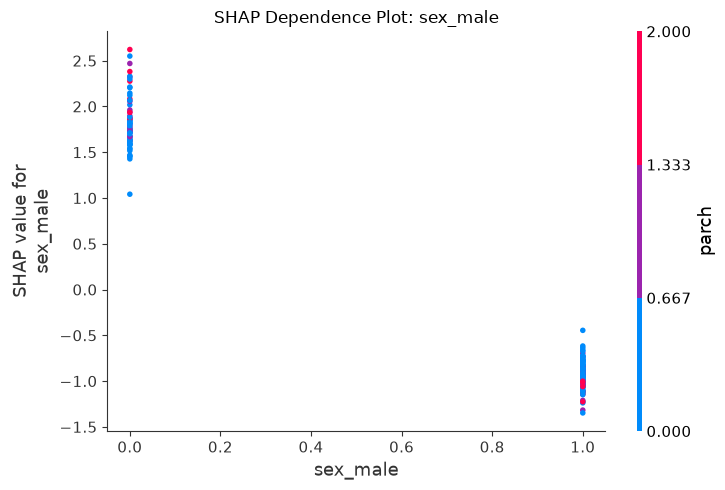


Feature: fare
SHAP selected colouring feature: sibsp


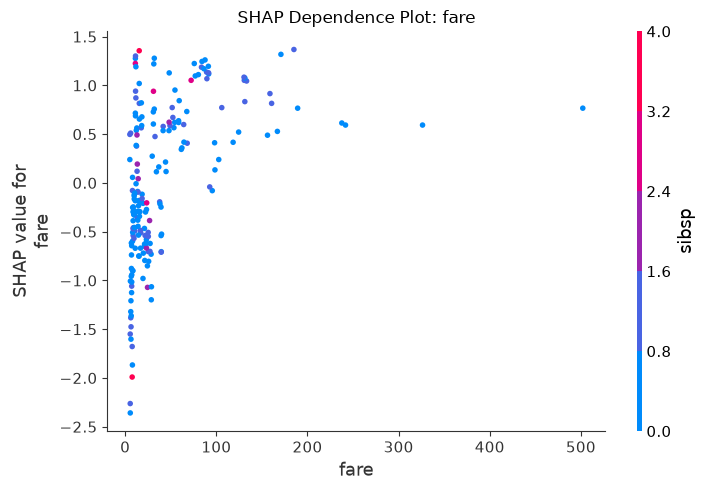


SHAP spread for sex_male:
                  min     max    mean  count
Feature Value                               
0              1.0415  2.6220  1.8293     68
1             -1.3477 -0.4455 -0.9336    132

SHAP spread for fare:
                  min     max    mean  count
Feature Value                               
5.09           0.2394  0.2394  0.2394      1
5.10           0.4972  0.4972  0.4972      1
5.51          -1.5495 -1.5495 -1.5495      1
5.52          -2.2621 -2.2621 -2.2621      1
5.58          -2.3583 -2.3583 -2.3583      1
...               ...     ...     ...    ...
189.20         0.7662  0.7662  0.7662      1
237.66         0.6144  0.6144  0.6144      1
241.72         0.5933  0.5933  0.5933      1
326.22         0.5933  0.5933  0.5933      1
502.04         0.7664  0.7664  0.7664      1

[197 rows x 4 columns]


In [33]:

import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt

# 1. Calculate mean absolute SHAP importance for each feature
shap_importance = np.abs(shap_values).mean(axis=0)

# 2. Find the top two most important features
importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "SHAP Importance": shap_importance
}).sort_values(by="SHAP Importance", ascending=False)

top_features = importance_df["Feature"].head(2).tolist()

print("Top two features:")
print(importance_df.head(2))

# 3. Create dependence plots for the top two features
for feature in top_features:

    # Find the feature SHAP selects for colouring
    interaction_indices = shap.utils.approximate_interactions(
        feature, shap_values, X_test
    )

    interaction_feature = X_test.columns[interaction_indices[0]]

    print("\nFeature:", feature)
    print("SHAP selected colouring feature:", interaction_feature)

    # Draw dependence plot
    shap.dependence_plot(
        feature,
        shap_values,
        X_test,
        interaction_index=interaction_feature,
        show=False
    )

    plt.title(f"SHAP Dependence Plot: {feature}")
    plt.tight_layout()
    plt.show()

# 4. Print SHAP values at different feature positions
for feature in top_features:

    feature_index = X_test.columns.get_loc(feature)

    result = pd.DataFrame({
        "Feature Value": X_test[feature].values,
        "SHAP Value": shap_values[:, feature_index]
    })

    print(f"\nSHAP spread for {feature}:")
    print(
        result.groupby("Feature Value")["SHAP Value"]
        .agg(["min", "max", "mean", "count"])
        .round(4)
    )


## Part C — Partial dependence

## TASK 06 — Build PDPs and compare them to SHAP

TOP THREE FEATURES:
 Feature  Importance
sex_male    1.238137
    fare    0.682719
  pclass    0.630541
Using manual PDP for: sex_male
Reason: ValueError('The column 1 contains integer data. Partial dependence plots are not supported for integer data: this can lead to implicit rounding with NumPy arrays or even errors with newer pandas versions. Please convert numerical features to floating point dtypes ahead of time to avoid problems.')


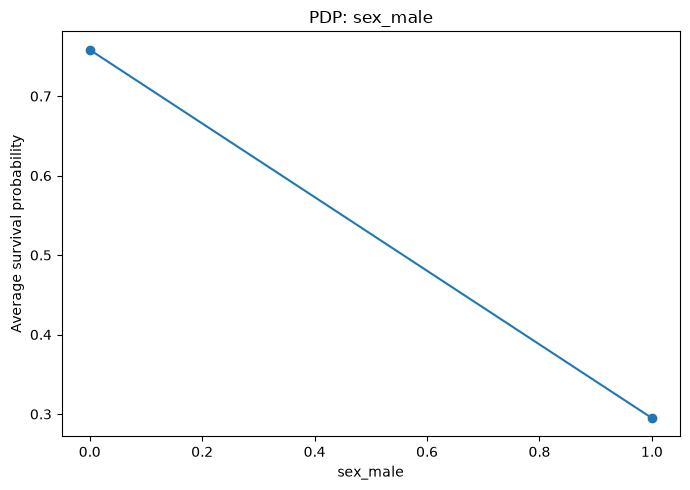

PartialDependenceDisplay worked for: fare


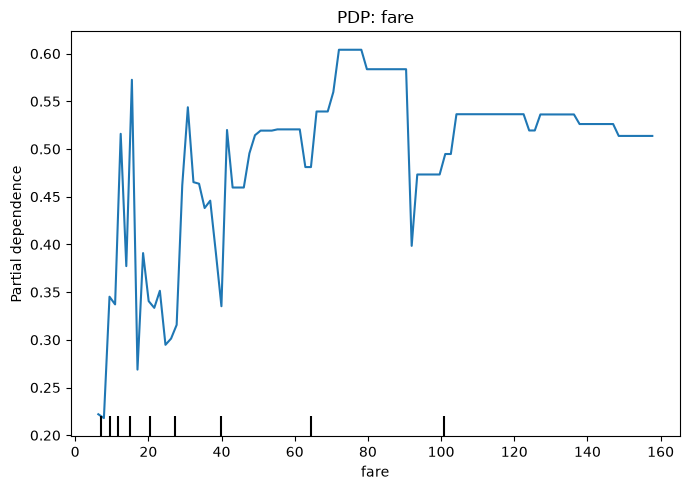

Using manual PDP for: pclass
Reason: ValueError('The column 0 contains integer data. Partial dependence plots are not supported for integer data: this can lead to implicit rounding with NumPy arrays or even errors with newer pandas versions. Please convert numerical features to floating point dtypes ahead of time to avoid problems.')


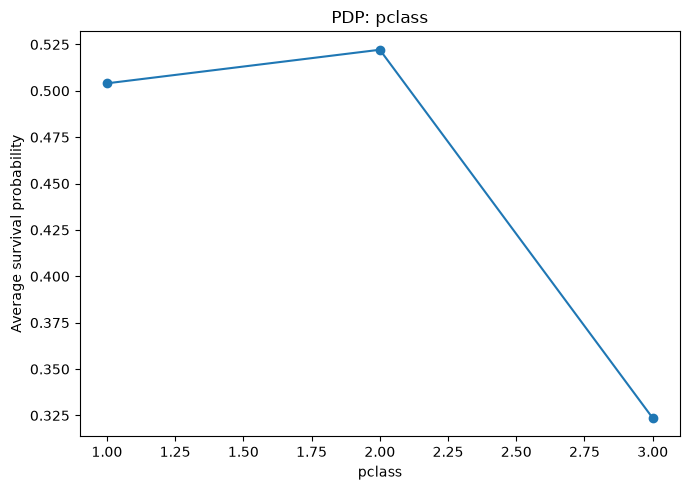

Using manual PDP for comparison: ValueError('The column 1 contains integer data. Partial dependence plots are not supported for integer data: this can lead to implicit rounding with NumPy arrays or even errors with newer pandas versions. Please convert numerical features to floating point dtypes ahead of time to avoid problems.')


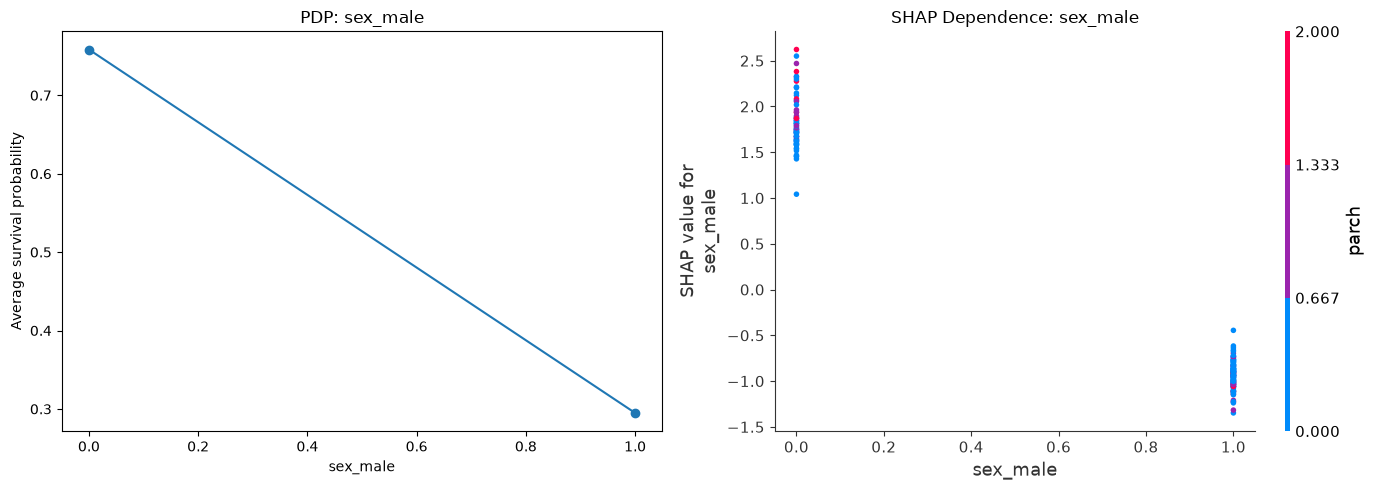

Using manual two-feature PDP: ValueError('The column 1 contains integer data. Partial dependence plots are not supported for integer data: this can lead to implicit rounding with NumPy arrays or even errors with newer pandas versions. Please convert numerical features to floating point dtypes ahead of time to avoid problems.')


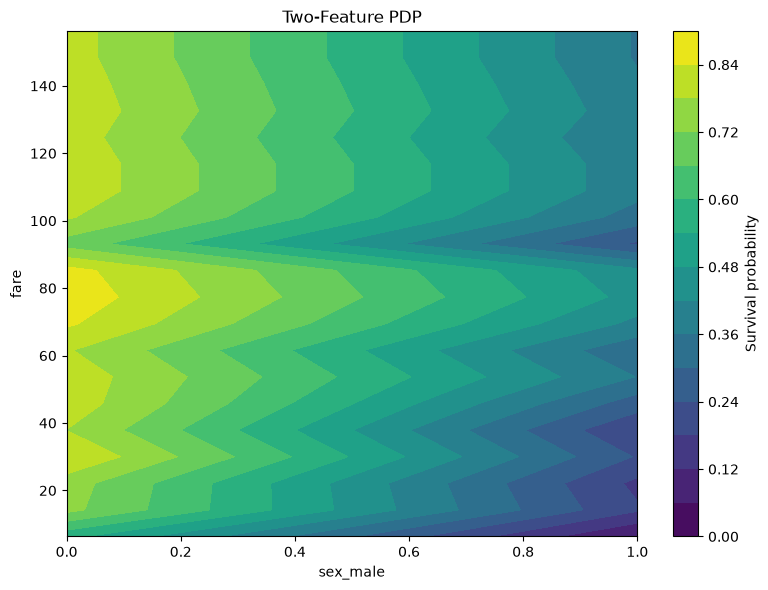


PDP VS SHAP COMPARISON:
                       Comparison                                                PDP                                        SHAP Dependence
 What each dot or line represents Line shows average predicted survival probability. Each dot represents one passenger's SHAP contribution.
        Whether spread is visible               No individual spread in average PDP.                     Yes, individual spread is visible.
 Whether interactions are visible               Two-feature PDP shows joint effects.                Dot colours show possible interactions.
Easier for a non-technical reader                                                PDP                             Requires more explanation.


In [34]:

import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt

from sklearn.inspection import PartialDependenceDisplay

# ------------------------------------------------
# 1. Find top three features using SHAP
# ------------------------------------------------

shap_importance = np.abs(shap_values).mean(axis=0)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": shap_importance
}).sort_values("Importance", ascending=False)

top_three = importance_df["Feature"].head(3).tolist()

print("TOP THREE FEATURES:")
print(importance_df.head(3).to_string(index=False))


# ------------------------------------------------
# 2. Helper functions for PDP calculations
# ------------------------------------------------

def get_feature_grid(feature):
    values = np.sort(X_test[feature].dropna().unique())

    # Use actual values for categorical or low-cardinality features
    if len(values) <= 10:
        return values

    # Use 20 points for continuous features
    return np.linspace(
        X_test[feature].quantile(0.05),
        X_test[feature].quantile(0.95),
        20
    )


def manual_pdp(feature, ax):
    grid = get_feature_grid(feature)
    predictions = []

    for value in grid:
        data = X_test.copy()
        data[feature] = value

        probability = model.predict_proba(data)[:, 1]
        predictions.append(probability.mean())

    ax.plot(grid, predictions, marker="o")
    ax.set_xlabel(feature)
    ax.set_ylabel("Average survival probability")
    ax.set_title(f"PDP: {feature}")


def manual_2d_pdp(feature1, feature2, ax):
    grid1 = get_feature_grid(feature1)
    grid2 = get_feature_grid(feature2)

    results = np.zeros((len(grid2), len(grid1)))

    for i, value2 in enumerate(grid2):
        for j, value1 in enumerate(grid1):
            data = X_test.copy()
            data[feature1] = value1
            data[feature2] = value2

            results[i, j] = model.predict_proba(data)[:, 1].mean()

    contour = ax.contourf(
        grid1, grid2, results,
        levels=15
    )

    ax.set_xlabel(feature1)
    ax.set_ylabel(feature2)
    ax.set_title("Two-Feature PDP")
    plt.colorbar(contour, ax=ax, label="Survival probability")


# ------------------------------------------------
# 3. Build PDPs for top three features
# ------------------------------------------------

for feature in top_three:

    fig, ax = plt.subplots(figsize=(7, 5))

    try:
        PartialDependenceDisplay.from_estimator(
            model,
            X_test,
            features=[feature],
            response_method="predict_proba",
            method="brute",
            target=1,
            kind="average",
            ax=ax
        )

        ax.set_title(f"PDP: {feature}")
        print("PartialDependenceDisplay worked for:", feature)

    except Exception as error:
        print("Using manual PDP for:", feature)
        print("Reason:", repr(error))

        manual_pdp(feature, ax)

    plt.tight_layout()
    plt.show()


# ------------------------------------------------
# 4. Place top feature PDP beside SHAP plot
# ------------------------------------------------

top_feature = top_three[0]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

try:
    PartialDependenceDisplay.from_estimator(
        model,
        X_test,
        features=[top_feature],
        response_method="predict_proba",
        method="brute",
        target=1,
        kind="average",
        ax=axes[0]
    )

    axes[0].set_title(f"PDP: {top_feature}")

except Exception as error:
    print("Using manual PDP for comparison:", repr(error))
    manual_pdp(top_feature, axes[0])

shap.dependence_plot(
    top_feature,
    shap_values,
    X_test,
    interaction_index="auto",
    ax=axes[1],
    show=False
)

axes[1].set_title(f"SHAP Dependence: {top_feature}")

plt.tight_layout()
plt.show()


# ------------------------------------------------
# 5. Build two-feature PDP using a tuple
# ------------------------------------------------

feature_pair = (top_three[0], top_three[1])

fig, ax = plt.subplots(figsize=(8, 6))

try:
    PartialDependenceDisplay.from_estimator(
        model,
        X_test,
        features=[feature_pair],
        response_method="predict_proba",
        method="brute",
        target=1,
        kind="average",
        ax=ax
    )

    ax.set_title(f"PDP: {feature_pair}")

except Exception as error:
    print("Using manual two-feature PDP:", repr(error))

    manual_2d_pdp(
        feature_pair[0],
        feature_pair[1],
        ax
    )

plt.tight_layout()
plt.show()


# ------------------------------------------------
# 6. PDP vs SHAP comparison table
# ------------------------------------------------

comparison = pd.DataFrame({
    "Comparison": [
        "What each dot or line represents",
        "Whether spread is visible",
        "Whether interactions are visible",
        "Easier for a non-technical reader"
    ],

    "PDP": [
        "Line shows average predicted survival probability.",
        "No individual spread in average PDP.",
        "Two-feature PDP shows joint effects.",
        "PDP"
    ],

    "SHAP Dependence": [
        "Each dot represents one passenger's SHAP contribution.",
        "Yes, individual spread is visible.",
        "Dot colours show possible interactions.",
        "Requires more explanation."
    ]
})

print("\nPDP VS SHAP COMPARISON:")
print(comparison.to_string(index=False))


Definition to use
Partial dependence plot: the model's average predicted output as one feature varies across its range. It shows overall behaviour, with individual variation averaged away.


\- **Business report:** I would use **PDP** because it clearly shows the average effect of a feature on passenger survival probability and is easier for non-technical people to understand.

\- **Model debugging:** I would use **SHAP dependence plots** because they show individual passenger contributions and help identify feature interactions and unusual prediction behaviour.

## Part D — Find where it breaks

## TASK 07 — Correlated features split the credit

In [35]:

import numpy as np
import pandas as pd
import shap
from xgboost import XGBClassifier

# 1. Original fare importance
original_shap = np.asarray(shap_values)

fare_index = X_test.columns.get_loc("fare")
fare_before = np.abs(original_shap[:, fare_index]).mean()

# 2. Create copies of the original datasets
X_train_copy = X_train.copy()
X_test_copy = X_test.copy()

# Add tiny random noise to fare
rng = np.random.default_rng(42)
noise_scale = X_train["fare"].std() * 0.001

X_train_copy["fare_copy"] = (
    X_train_copy["fare"] +
    rng.normal(0, noise_scale, len(X_train_copy))
)

X_test_copy["fare_copy"] = (
    X_test_copy["fare"] +
    rng.normal(0, noise_scale, len(X_test_copy))
)

# 3. Confirm correlation
correlation = X_train_copy["fare"].corr(
    X_train_copy["fare_copy"]
)
print("Fare correlation:", round(correlation, 5))

# 4. Train an identical XGBoost model with the extra feature
model_copy = XGBClassifier(
    n_estimators=300,
    learning_rate=0.1,
    max_depth=3,
    random_state=42,
    eval_metric="logloss"
)

model_copy.fit(X_train_copy, y_train)

# 5. Calculate new SHAP values
explainer_copy = shap.TreeExplainer(model_copy)
shap_values_copy = explainer_copy.shap_values(X_test_copy)

# 6. Calculate new feature importances
new_shap = np.asarray(shap_values_copy)

fare_index_new = X_test_copy.columns.get_loc("fare")
copy_index_new = X_test_copy.columns.get_loc("fare_copy")

fare_after = np.abs(new_shap[:, fare_index_new]).mean()
copy_after = np.abs(new_shap[:, copy_index_new]).mean()

# 7. Display comparison
print("\nSHAP Importance Comparison")
print("-------------------------")
print("Fare before:", round(fare_before, 5))
print("Fare after:", round(fare_after, 5))
print("Fare_copy after:", round(copy_after, 5))
print("Combined importance:", round(fare_after + copy_after, 5))


Fare correlation: 1.0

SHAP Importance Comparison
-------------------------
Fare before: 0.68272
Fare after: 0.55174
Fare_copy after: 0.28149
Combined importance: 0.83323


### **1. What wrong conclusion would you draw from the ranking after duplication?**

I might conclude that `fare` is less important and `fare_copy` is a separate important feature. Actually, both contain almost the same information, so SHAP importance gets divided between them.

### **2. Name two correlated features in a business dataset.**

- **Sales and Revenue:** Higher sales usually mean higher revenue.
- **Advertising Spend and Marketing Spend:** Both may increase together.

### **3. What should you check before reading a SHAP importance ranking?**

- Check feature correlations.
- Look for duplicate or highly correlated features.
- Check whether features contain overlapping information.

**Conclusion:** Always check feature relationships before interpreting SHAP rankings because correlated features can share importance and make individual feature rankings misleading.


QUESTION : #### Required conclusion

Write a two-sentence warning you would give a teammate about reading SHAP importance on a dataset with correlated features

ANSWER :SHAP importance may be divided among highly correlated features, making individual features appear less important than they actually are. Always check feature correlations before interpreting SHAP rankings to avoid misleading conclusions.

## TASK 08 — Measure the computational cost

In [36]:

import time
import numpy as np
import pandas as pd
import shap

# 1. Prepare data
X_test_data = X_test.copy()
X_train_data = X_train.copy()

# Use 50 background samples
background = shap.sample(X_train_data, 50, random_state=42)

# Use 30 test rows for KernelExplainer
X_small = X_test_data.iloc[:30].copy()

# 2. TreeExplainer
tree_explainer = shap.TreeExplainer(model)

start = time.perf_counter()

tree_shap_values = tree_explainer.shap_values(X_test_data)

tree_time = time.perf_counter() - start

tree_ms_per_row = (tree_time * 1000) / len(X_test_data)

# 3. Prediction wrapper for KernelExplainer
def predict_function(data):
    data = pd.DataFrame(data, columns=X_train_data.columns)
    return model.predict_proba(data)

# 4. KernelExplainer
kernel_explainer = shap.KernelExplainer(
    predict_function,
    background
)

start = time.perf_counter()

kernel_shap_values = kernel_explainer.shap_values(
    X_small,
    nsamples=100
)

kernel_time = time.perf_counter() - start

kernel_ms_per_row = (kernel_time * 1000) / len(X_small)

# 5. Calculate per-row ratio
ratio = kernel_ms_per_row / tree_ms_per_row

# 6. Estimate KernelExplainer time for 100,000 rows
estimated_ms = kernel_ms_per_row * 100000

estimated_hours = estimated_ms / (1000 * 60 * 60)
estimated_days = estimated_hours / 24

# 7. Display results
print("=" * 50)
print("SHAP EXECUTION TIME COMPARISON")
print("=" * 50)

print(f"TreeExplainer total time: {tree_time:.4f} seconds")
print(f"TreeExplainer per row: {tree_ms_per_row:.4f} ms")

print("-" * 50)

print(f"KernelExplainer total time: {kernel_time:.4f} seconds")
print(f"KernelExplainer per row: {kernel_ms_per_row:.4f} ms")

print("-" * 50)

print(f"KernelExplainer is {ratio:.2f} times slower per row")

print("-" * 50)

print("Estimated KernelExplainer time for 100,000 rows:")
print(f"{estimated_hours:.2f} hours")
print(f"{estimated_days:.2f} days")

print("=" * 50)


100%|██████████| 30/30 [00:00<00:00, 103.67it/s]

SHAP EXECUTION TIME COMPARISON
TreeExplainer total time: 0.0094 seconds
TreeExplainer per row: 0.0468 ms
--------------------------------------------------
KernelExplainer total time: 0.2911 seconds
KernelExplainer per row: 9.7046 ms
--------------------------------------------------
KernelExplainer is 207.26 times slower per row
--------------------------------------------------
Estimated KernelExplainer time for 100,000 rows:
0.27 hours
0.01 days


Definitions to use
TreeExplainer: computes SHAP values exactly by exploiting tree structure. Fast, but only works for tree-based models.
KernelExplainer: works for any model, but approximates by sampling, which is far slower.

#### Required conclusion

Write a one-line rule for when to use each explainer, and one sentence on what you would do if you had to explain a non-tree model on a very large dataset.  give answer?

- **TreeExplainer:** Use it for tree-based models because it is fast and efficient.
- **KernelExplainer:** Use it for non-tree models because it works with different model types but is slower.

**For a non-tree model on a very large dataset:** I would use KernelExplainer on a small representative sample instead of explaining all rows to reduce computation time.

## Part E — Intern-style delivery

## TASK 09 — Write the interpretation paragraph

### **Updated final paragraph**

Our Titanic survival model achieved a test ROC-AUC of **0.8452**. The top three drivers of survival were **sex_male**, **fare**, and **pclass**, in that order. Female passengers generally had a higher predicted chance of survival than male passengers. Higher fares generally pushed predictions towards survival, while first-class passengers generally had better predicted survival chances than third-class passengers. The effect of fare varied across passengers rather than increasing consistently. In real-world context, these findings suggest that gender and socioeconomic status influenced survival chances during the Titanic disaster. One limitation is that fare and passenger class are correlated, so their individual importance may overlap, and the model is based on historical data.

## TASK 10 — Explain a prediction to a sceptical reader

In [ ]:
# Get predicted probabilities
y_prob = model.predict_proba(X_test)[:, 1]

# Convert probabilities into predicted classes
y_pred = (y_prob >= 0.5).astype(int)

# Find incorrect predictions
wrong = np.where(y_pred != y_test.values)[0]

if len(wrong) > 0:
    # Find the most confident wrong prediction
    confidence = np.abs(y_prob[wrong] - 0.5)
    idx = wrong[np.argmax(confidence)]

    print("Passenger index:", idx)
    print("Actual survival:", y_test.iloc[idx])
    print("Predicted survival:", y_pred[idx])
    print("Prediction probability:", y_prob[idx])
else:
    print("No confident errors. Finding most confident correct prediction.")

    correct = np.where(y_pred == y_test.values)[0]
    confidence = np.abs(y_prob[correct] - 0.5)
    idx = correct[np.argmax(confidence)]

    print("Passenger index:", idx)
    print("Actual survival:", y_test.iloc[idx])
    print("Predicted survival:", y_pred[idx])
    print("Prediction probability:", y_prob[idx])


In [ ]:
shap.plots.waterfall(shap_values[idx])

** Written conclusion:

Use this paragraph if your model made a confident incorrect prediction:

The model confidently predicted that this passenger would not survive, but the passenger actually survived. The prediction was influenced by features such as gender, age, and fare, as shown in the waterfall plot. These features pushed the prediction toward non-survival, but the model could not correctly predict this individual passenger's outcome. Next, I would investigate other passenger details and check why similar passengers were incorrectly classified.

Note: Change the conclusion according to your actual waterfall plot. If there are no confident errors, mention that the model made no confident errors and explain the most confident correct prediction instead.